# Laboratorio E1 · Series de tiempo del precio de la salud en México

**Observatorio de Abastecimiento Inteligente para Consultorios de Colima** · Análisis Estadístico, unidad 3 (temas 3.1 a 3.3).

**Pregunta E1 (propuesta E0):** ¿cómo evolucionan los precios de los insumos médicos y cuál podría ser su comportamiento futuro?

Nuestras capturas de tiendas dentales empezaron en noviembre de 2026 y no alcanzan los 36 periodos que pide el pronóstico. Por eso usamos una serie oficial larga del mismo sector:

| | |
|---|---|
| **Variable que se pronostica** | Índice de precios al consumidor de **Salud** (división 06 de COICOP: medicamentos, material de curación, aparatos terapéuticos y servicios médicos), México, mensual, base 2015 = 100 |
| **Segunda variable** | Índice general de precios al consumidor (para la correlación cruzada) |
| **Fuente** | OCDE, `DSD_PRICES@DF_PRICES_ALL`. El dato primario es el INPC de INEGI |
| **Captura** | `python -m scripts.captura_ipc_salud` guarda el CSV original y un manifiesto con SHA-256 en `datos/bronce/ipc_salud/` |
| **Periodos** | 265 meses (julio 2002 a julio 2024) |

Toda la lógica vive en [`src/series_e1.py`](../src/series_e1.py) y tiene pruebas en `tests/test_series_e1.py`. Este notebook la llama, muestra las gráficas y explica cada resultado. Para reproducirlo desde la raíz del repositorio:

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-lab.txt
.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace laboratorio/e1_series.ipynb
```

In [1]:
import os, json, warnings
from pathlib import Path
if Path.cwd().name == "laboratorio":
    os.chdir("..")  # las rutas del proyecto son relativas a la raíz
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats

from src import series_e1 as s

FIG = Path("datos/oro/series_e1/figuras")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#2563eb", "#ea580c", "#6b7280"

captura = s.ultima_captura()
datos = s.cargar_series(captura)   # verifica el SHA-256 del manifiesto antes de leer
salud = datos["salud"]
print("Captura Bronce:", captura.as_posix())
print(json.loads((captura / "manifiesto.json").read_text(encoding="utf-8"))["cobertura"])
datos.tail()

Captura Bronce: datos/bronce/ipc_salud/20261127T223048220680Z
{'CP06': {'periodos': 265, 'inicio': '2002-07', 'fin': '2024-07'}, '_T': {'periodos': 667, 'inicio': '1969-01', 'fin': '2024-07'}}


EXPENDITURE,salud,general
fecha,,
2024-03-01,153.3265,152.9470
2024-04-01,154.0751,153.2561
2024-05-01,154.8211,152.9721
2024-06-01,155.2557,153.5505
2024-07-01,155.6715,155.1579


## 1. Caracterización de la serie

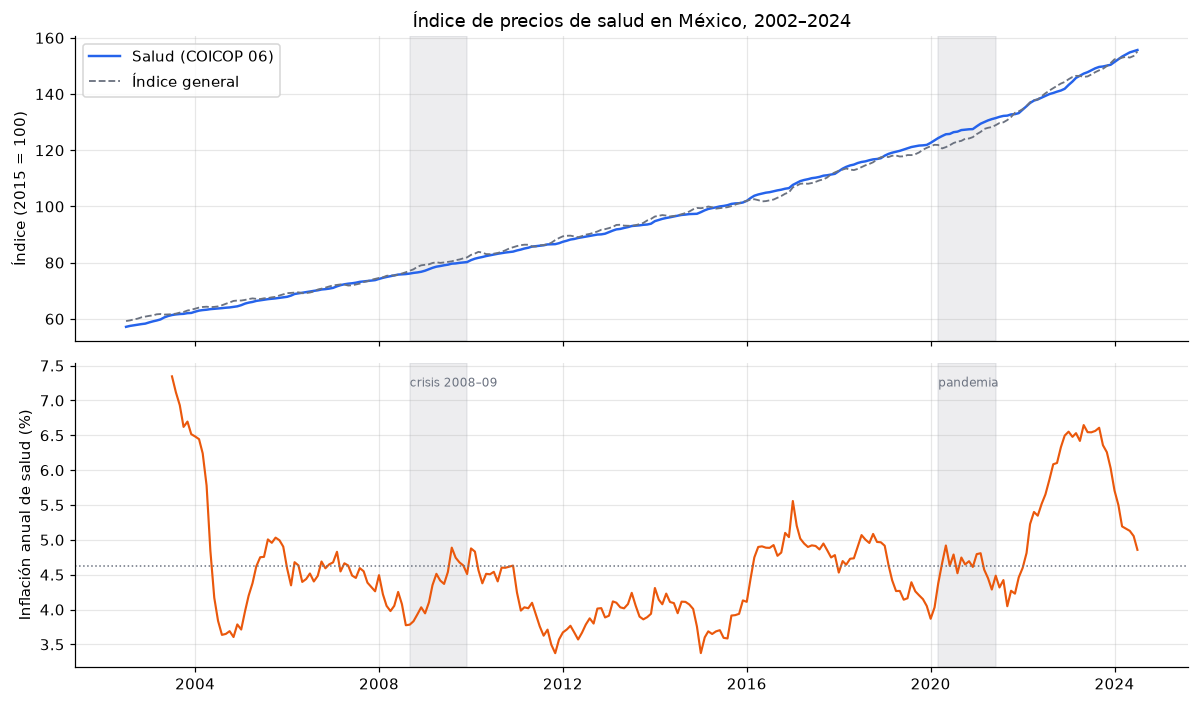

inicio                          2002-07
fin                             2024-07
periodos                            265
minimo                         57.16159
maximo                         155.6715
crecimiento_total_pct        172.335847
inflacion_anual_media_pct      4.618457
inflacion_anual_max_pct        7.345772
mes_inflacion_anual_max         2003-07
dtype: object

In [2]:
carac = s.caracterizar(salud)
anual = salud.pct_change(12) * 100
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
a1.plot(salud, color=AZUL, lw=1.6, label="Salud (COICOP 06)")
a1.plot(datos["general"], color=GRIS, lw=1.2, ls="--", label="Índice general")
a1.set_ylabel("Índice (2015 = 100)"); a1.legend(loc="upper left"); a1.set_title("Índice de precios de salud en México, 2002–2024")
a2.plot(anual, color=NARANJA, lw=1.4); a2.axhline(anual.mean(), color=GRIS, ls=":", lw=1)
a2.set_ylabel("Inflación anual de salud (%)")
for inicio, fin, txt in [("2008-09", "2009-12", "crisis 2008–09"), ("2020-03", "2021-06", "pandemia")]:
    for a in (a1, a2):
        a.axvspan(pd.Timestamp(inicio), pd.Timestamp(fin), color=GRIS, alpha=.12)
    a2.text(pd.Timestamp(inicio), anual.max() * .98, txt, fontsize=8, color=GRIS)
fig.tight_layout(); fig.savefig(FIG / "01_serie.png", bbox_inches="tight"); plt.show()
pd.Series(carac)

**Lectura:**

- **Tendencia:** creciente y casi lineal. El índice pasó de 57.2 a 155.7, un aumento de 172 % en 22 años. La inflación anual de salud promedia **4.6 %**, apenas por encima del índice general.
- **Estacionalidad:** hay saltos que se repiten cada enero, cuando se actualizan las listas de precios. Se confirma en la descomposición.
- **Ciclos y cambios estructurales:** la inflación de salud fue más alta en 2002–2004 (máximo de 7.3 % en julio de 2003). Bajó a cerca de 3–4 % entre 2015 y 2019 y repuntó después de la pandemia (2021–2023). No hay un quiebre de nivel. Sí hay periodos de mayor y menor inflación, por eso conviene evaluar los modelos en varias ventanas y no solo en una.

## 2. Descomposición: ¿aditiva o multiplicativa?

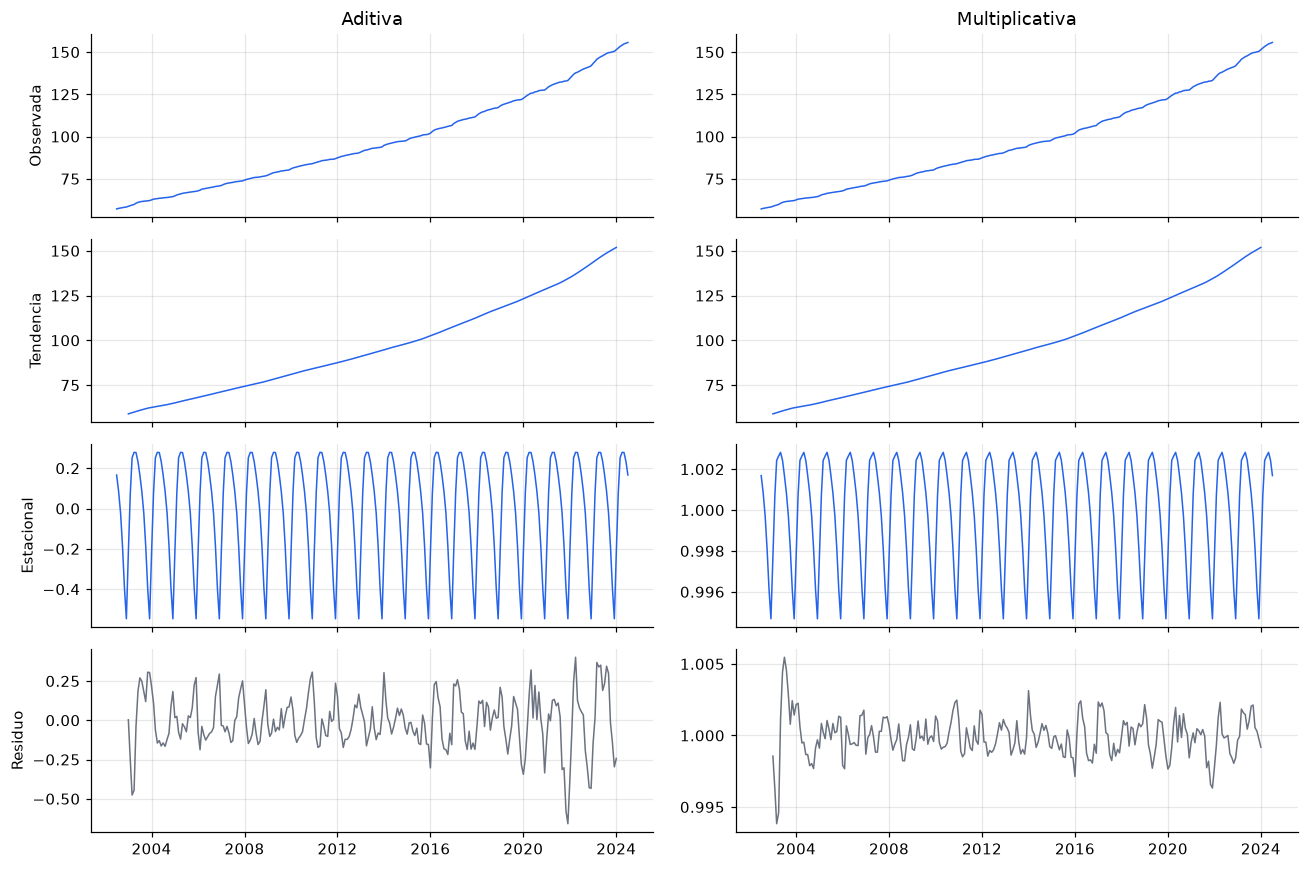

{'corr_amplitud_nivel': 0.548,
 'desv_residuo_aditivo': 0.17,
 'desv_residuo_multiplicativo_en_puntos': 0.135,
 'fuerza_estacional_aditiva': 0.713,
 'eleccion': 'multiplicativa'}

In [3]:
desc = s.comparar_descomposiciones(salud)
fig, ejes = plt.subplots(4, 2, figsize=(12, 8), sharex=True)
for col, (nombre, d) in enumerate([("Aditiva", desc["aditiva"]), ("Multiplicativa", desc["multiplicativa"])]):
    for fila, (comp, etiqueta) in enumerate([(d.observed, "Observada"), (d.trend, "Tendencia"), (d.seasonal, "Estacional"), (d.resid, "Residuo")]):
        ax = ejes[fila, col]
        ax.plot(comp, color=AZUL if fila < 3 else GRIS, lw=1)
        if fila == 0: ax.set_title(nombre)
        if col == 0: ax.set_ylabel(etiqueta)
fig.tight_layout(); fig.savefig(FIG / "02_descomposicion.png", bbox_inches="tight"); plt.show()
{k: round(v, 3) if isinstance(v, float) else v for k, v in desc.items() if k not in ("aditiva", "multiplicativa")}

**Decisión: modelo multiplicativo.**

- La amplitud estacional de cada año (diferencia entre su mes más alto y su mes más bajo, ya sin tendencia) **crece con el nivel** de la serie: correlación r = 0.55 entre amplitud y nivel. Si la estacionalidad fuera aditiva, la amplitud sería constante y esa correlación estaría cerca de 0. Esto tiene sentido económico: los ajustes de enero son porcentajes del precio, no montos fijos en pesos.
- El residuo multiplicativo, expresado en puntos del índice, es menor que el aditivo (0.13 contra 0.17).
- La fuerza estacional es 0.71 en una escala de 0 a 1, así que la estacionalidad es clara y hay que modelarla.

Por esto, Holt-Winters se ajusta con estacionalidad **multiplicativa**.

## 3. Estacionariedad: prueba de Dickey-Fuller aumentada

In [4]:
(d, D), adf = s.elegir_diferenciacion(salud)
tabla_adf = pd.DataFrame(adf)[["serie", "estadistico", "critico_5pct", "p_valor", "rezagos", "estacionaria"]]
print(f"Diferenciación elegida: d = {d} (regular), D = {D} (estacional, periodo 12)")
tabla_adf.round(4)

Diferenciación elegida: d = 1 (regular), D = 1 (estacional, periodo 12)


,serie,estadistico,critico_5pct,p_valor,rezagos,estacionaria
0,"d=0, D=0",3.0777,-2.8732,1.0000,14,False
1,"d=1, D=0",-0.7178,-2.8732,0.8421,13,False
2,"d=0, D=1",-0.1650,-2.8737,0.9426,13,False
3,"d=1, D=1",-5.3403,-2.8737,0.0000,12,True
4,"d=2, D=0",-7.5409,-2.8732,0.0000,12,True


**Lectura:** H₀ de la prueba ADF: la serie tiene raíz unitaria, es decir, **no** es estacionaria.

- **Nivel (d=0):** p = 1.0. Es claramente no estacionaria por la tendencia.
- **Una diferencia regular (d=1):** p = 0.84. Todavía no es estacionaria, porque queda el patrón de cada enero.
- **Solo la diferencia estacional (D=1):** p = 0.94. Tampoco basta.
- **d=1 y D=1:** p < 0.001. Se rechaza H₀ y la serie ya es estacionaria. **Esta es la diferenciación que se usa.**
- **d=2:** también rechaza H₀, pero deja la estacionalidad sin tratar y diferencia de más. Por eso se elige la combinación menos diferenciada que logra estacionariedad: d=1, D=1.

## 4. Autocorrelación: ACF y PACF de la serie estacionaria

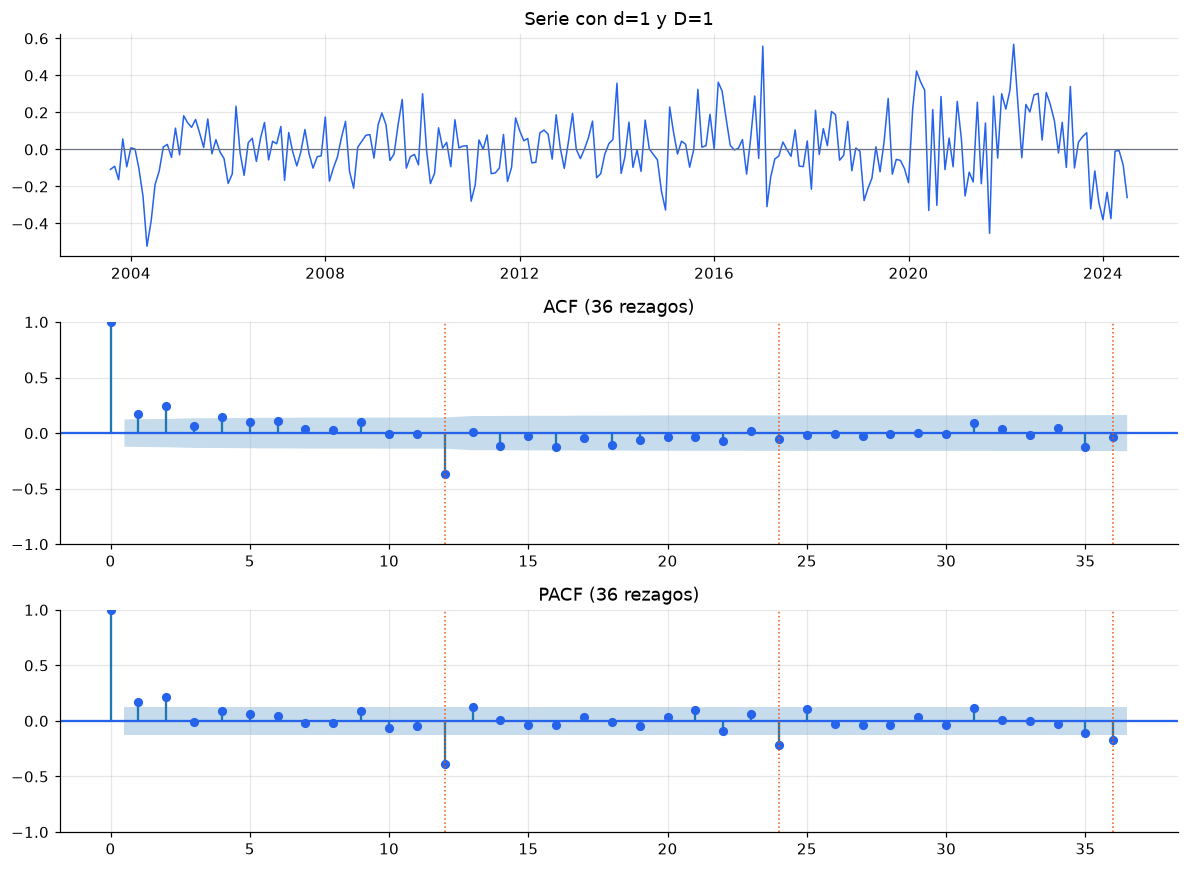

In [5]:
estacionaria = s.diferenciar(salud, d, D)
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(11, 8))
a1.plot(estacionaria, color=AZUL, lw=1); a1.axhline(0, color=GRIS, lw=.8); a1.set_title("Serie con d=1 y D=1")
plot_acf(estacionaria, lags=36, ax=a2, color=AZUL, title="ACF (36 rezagos)")
plot_pacf(estacionaria, lags=36, ax=a3, color=AZUL, method="ywm", title="PACF (36 rezagos)")
for a in (a2, a3):
    for k in (12, 24, 36): a.axvline(k, color=NARANJA, ls=":", lw=1)
fig.tight_layout(); fig.savefig(FIG / "03_acf_pacf.png", bbox_inches="tight"); plt.show()

**Lectura** (banda de significancia ±0.12):

- **Rezagos estacionales (12, 24, 36, en naranja):** la ACF tiene un único pico negativo grande en el rezago 12 (−0.37) y luego se corta. La PACF decae en 12, 24 y 36 (−0.39, −0.22, −0.17). Ese es el patrón de una **media móvil estacional de orden 1**: Q = 1, P = 0.
- **Rezagos cortos:** la ACF y la PACF son significativas en 1 y 2 (entre 0.17 y 0.24) y después se apagan. Eso sugiere una parte ARMA pequeña, con p y q entre 1 y 3.
- Con esa guía se buscaron p, q ∈ {0,1,2,3} y P, Q ∈ {0,1} con d=1 y D=1 fijos, y se ordenó por AIC. El AIC solo compara modelos con la misma diferenciación, por eso d y D no entran en la búsqueda.

In [6]:
entrenamiento, prueba = s.separar(salud)
busqueda = s.seleccionar_arima(entrenamiento, d, D)
mejor = busqueda.iloc[0]
orden = tuple(int(mejor[c]) for c in ("p", "d", "q", "P", "D", "Q"))
print("SARIMA elegido por AIC:", f"({orden[0]},{orden[1]},{orden[2]})({orden[3]},{orden[4]},{orden[5]})[12]")
busqueda.head(8).round(2)

SARIMA elegido por AIC: (1,1,3)(0,1,1)[12]


,p,d,q,P,D,Q,AIC,BIC
0,1,1,3,0,1,1,-264.26,-243.38
1,2,1,3,0,1,1,-262.59,-238.22
2,3,1,1,0,1,1,-262.38,-241.49
3,1,1,3,1,1,1,-262.32,-237.95
4,1,1,1,0,1,1,-261.64,-247.72
5,2,1,1,0,1,1,-261.50,-244.10
6,1,1,2,0,1,1,-261.03,-243.63
7,1,1,1,1,1,1,-259.76,-242.36


El modelo con menor AIC es **SARIMA(1,1,3)(0,1,1)[12]**. Concuerda con la lectura de ACF y PACF: Q = 1 estacional y una parte ARMA corta. El quinto lugar, (1,1,1)(0,1,1), es el de menor BIC: es más simple y su AIC está a menos de 3 puntos. Se conserva el de menor AIC, como pide la rúbrica, y en la sección 6 se verifica que sus residuos sean ruido blanco.

## 5. Correlación cruzada con el índice general

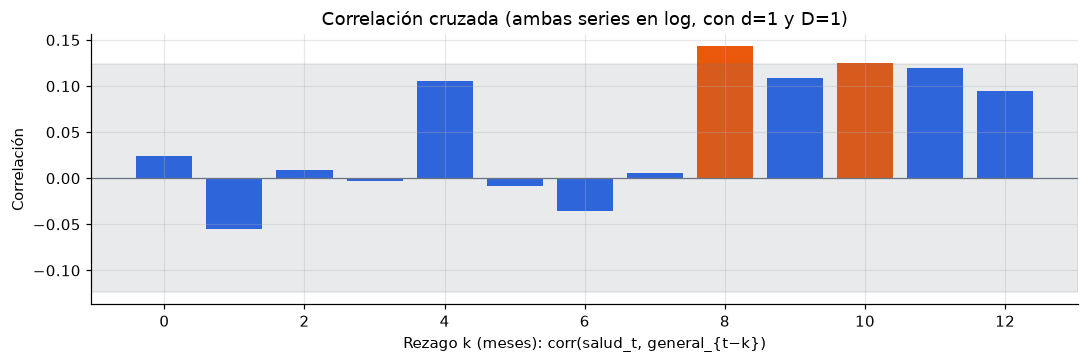

,0,1,2,3,4,5,6,7,8,9,10,11,12
rezago_meses,0,1,2,3,4,5,6,7,8,9,10,11,12
correlacion,0.024,-0.055,0.009,-0.003,0.105,-0.009,-0.036,0.006,0.143,0.109,0.125,0.12,0.095
significativa,False,False,False,False,False,False,False,False,True,False,True,False,False


In [7]:
cruzada, banda = s.correlacion_cruzada(salud, datos["general"])
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(cruzada.rezago_meses, cruzada.correlacion, color=[NARANJA if x else AZUL for x in cruzada.significativa])
ax.axhspan(-banda, banda, color=GRIS, alpha=.15); ax.axhline(0, color=GRIS, lw=.8)
ax.set_xlabel("Rezago k (meses): corr(salud_t, general_{t−k})"); ax.set_ylabel("Correlación")
ax.set_title("Correlación cruzada (ambas series en log, con d=1 y D=1)")
fig.tight_layout(); fig.savefig(FIG / "04_correlacion_cruzada.png", bbox_inches="tight"); plt.show()
cruzada.round(3).T

**Lectura:** primero se quitan tendencia y estacionalidad de las dos series (logaritmo, d=1 y D=1). Sin ese paso, cualquier par de índices de precios parece muy correlacionado solo porque los dos suben y comparten el calendario de enero.

- **Mismo mes (k = 0):** la correlación es prácticamente nula (0.02). Los cambios no anticipados del precio de la salud no van al mismo ritmo que los de la inflación general.
- **Rezagos de 8 y 10 meses:** hay correlaciones positivas pequeñas (≈0.13–0.14) que apenas pasan la banda. Se probaron 13 rezagos, así que una o dos de esas correlaciones pueden salir significativas solo por azar. Esto **no** basta para usar la inflación general como predictor.

**Implicación para el consultorio:** el precio de sus insumos de salud tiene su propia dinámica y conviene pronosticarlo con su propia serie, no deducirlo de la inflación general.

## 6. Cuatro modelos y selección con datos que no vieron

In [8]:
modelos = s.ajustar_modelos(entrenamiento, orden)
tabla, pron_prueba = s.comparar_en_prueba(modelos, prueba)
print(f"Entrenamiento: {entrenamiento.index.min():%Y-%m} a {entrenamiento.index.max():%Y-%m} ({len(entrenamiento)} meses)")
print(f"Prueba:        {prueba.index.min():%Y-%m} a {prueba.index.max():%Y-%m} ({len(prueba)} meses, no usados para ajustar)")
print({n: {k: round(v, 3) for k, v in s.parametros(m).items()} for n, m in modelos.items() if n != "SARIMA"})
tabla.round(3)

Entrenamiento: 2002-07 a 2023-07 (253 meses)
Prueba:        2023-08 a 2024-07 (12 meses, no usados para ajustar)
{'Suavizamiento simple': {'smoothing_level': 1.0}, 'Holt': {'smoothing_level': 1.0, 'smoothing_trend': 0.744}, 'Holt-Winters': {'smoothing_level': 1.0, 'smoothing_trend': 0.162, 'smoothing_seasonal': 0.0}}


,modelo,MAE,RMSE,MAPE
0,Holt,0.537,0.654,0.353
1,Holt-Winters,0.920,1.079,0.599
2,SARIMA,0.979,1.163,0.637
3,Suavizamiento simple,3.715,4.362,2.419


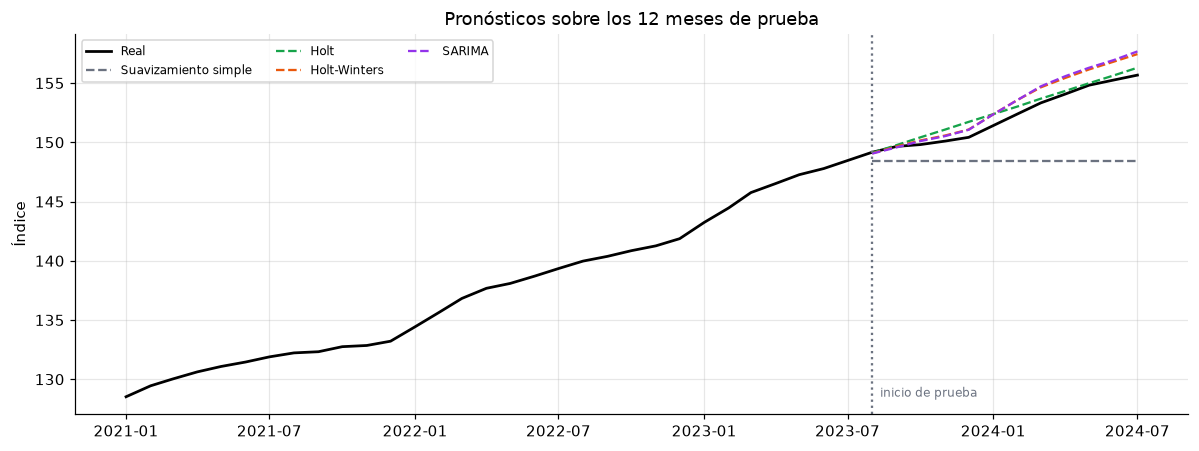

In [9]:
colores = {"Suavizamiento simple": GRIS, "Holt": "#16a34a", "Holt-Winters": NARANJA, "SARIMA": "#9333ea"}
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(salud["2021-01":], color="black", lw=1.8, label="Real")
for nombre in pron_prueba:
    ax.plot(pron_prueba[nombre], color=colores[nombre], lw=1.5, ls="--", label=nombre)
ax.axvline(prueba.index[0], color=GRIS, ls=":"); ax.text(prueba.index[0], salud["2021-01":].min(), "  inicio de prueba", color=GRIS, fontsize=8)
ax.set_title("Pronósticos sobre los 12 meses de prueba"); ax.set_ylabel("Índice"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "05_prueba.png", bbox_inches="tight"); plt.show()

**Lectura de la ventana de prueba (agosto 2023 a julio 2024):**

- **Holt** tuvo el menor error: RMSE 0.65, MAPE 0.35 %.
- **Holt-Winters** fue segundo (RMSE 1.08) y **SARIMA** tercero (RMSE 1.16).
- **Suavizamiento simple** queda muy atrás (RMSE 4.36), como se esperaba: pronostica una línea plana en una serie con tendencia.

Que un modelo **sin estacionalidad** gane en una sola ventana de 12 meses puede ser azar de esa ventana. Para comprobarlo se repite la prueba en las tres ventanas anuales más recientes, con el mismo procedimiento y cada modelo reajustado solo con el pasado de cada ventana.

In [10]:
detalle, promedio = s.validacion_por_origenes(salud, orden)
display(detalle.pivot(index="modelo", columns="ventana", values="RMSE").round(3))
promedio.round(3)

ventana,2021-08 a 2022-07,2022-08 a 2023-07,2023-08 a 2024-07
modelo,,,
Holt,1.181,1.492,0.654
Holt-Winters,0.996,1.010,1.079
SARIMA,0.974,1.283,1.163
Suavizamiento simple,4.309,5.514,4.362


,modelo,MAE,RMSE,MAPE
0,Holt-Winters,0.829,1.029,0.568
1,Holt,0.896,1.109,0.624
2,SARIMA,0.935,1.140,0.640
3,Suavizamiento simple,3.936,4.728,2.706


Promediando las tres ventanas, **Holt-Winters tiene el menor error** (RMSE 1.03, MAPE 0.57 %), seguido de Holt (1.11) y SARIMA (1.14).

- **Holt** ganó solo la ventana más reciente; en la de 2022–2023 fue el peor de los tres modelos con tendencia (RMSE 1.49).
- **SARIMA** ganó por poco la primera ventana.
- **Holt-Winters** fue el más estable: RMSE de 1.00, 1.01 y 1.08.

### Puerta de calidad 3: supuestos de los residuos

Un modelo con buen error pero residuos autocorrelacionados deja información sin usar, y su intervalo de predicción no es confiable. La regla del proyecto: *el hallazgo se publica con un método que cumpla el supuesto, o no se publica*. Se aplica Ljung-Box (H₀: no hay autocorrelación hasta el rezago 12 o 24) a los residuos de entrenamiento de los cuatro modelos, sin contar los meses de arranque.

In [11]:
menor_error, publicado, diagnosticos = s.aplicar_puerta_supuestos(tabla, modelos)
filas = []
for nombre, dg in diagnosticos.items():
    filas.append({"modelo": nombre,
                  "Ljung-Box p (12)": dg["ljung_box"][0]["p_valor"], "Ljung-Box p (24)": dg["ljung_box"][1]["p_valor"],
                  "sin autocorrelación": dg["sin_autocorrelacion"], "ARCH p (12)": dg["arch_p_valor"],
                  "var. último/primer tercio": dg["razon_varianza_final_inicial"]})
print("Menor error en la prueba:", menor_error, "| Modelo publicado:", publicado)
pd.DataFrame(filas).set_index("modelo").round(4)

Menor error en la prueba: Holt | Modelo publicado: Holt-Winters


,Ljung-Box p (12),Ljung-Box p (24),sin autocorrelación,ARCH p (12),var. último/primer tercio
modelo,,,,,
Suavizamiento simple,0.0000,0.0000,False,0.0000,5.6424
Holt,0.0000,0.0000,False,0.0000,5.2065
Holt-Winters,0.7539,0.7246,True,0.0751,2.6379
SARIMA,0.9089,0.8983,True,0.5079,2.3668


**Resultado de la puerta:**

- **Holt** (y el suavizamiento simple) **no pasan**: Ljung-Box tiene p < 0.001. Como Holt no modela la estacionalidad, el patrón de enero queda en los residuos. Su buen resultado en la última ventana no compensa eso, y su intervalo de predicción no sería válido.
- **Holt-Winters** pasa (p = 0.75 y 0.73) y **SARIMA** también (p = 0.91 y 0.90).

**Modelo publicado: Holt-Winters** (tendencia aditiva, estacionalidad multiplicativa). Es el de menor error de los que cumplen los supuestos en la última ventana, y además es el de menor error promedio en las tres ventanas.

**Varianza:** la prueba ARCH no detecta heterocedasticidad condicional en ninguno de los dos modelos válidos (p = 0.08 en Holt-Winters y 0.51 en SARIMA). Aun así, la varianza del último tercio de los residuos es más del doble que la del primero (2.6 y 2.4 veces), por los años de mayor inflación posteriores a 2021. Se reporta como limitación: el intervalo puede quedarse corto si vuelve un periodo de inflación alta.

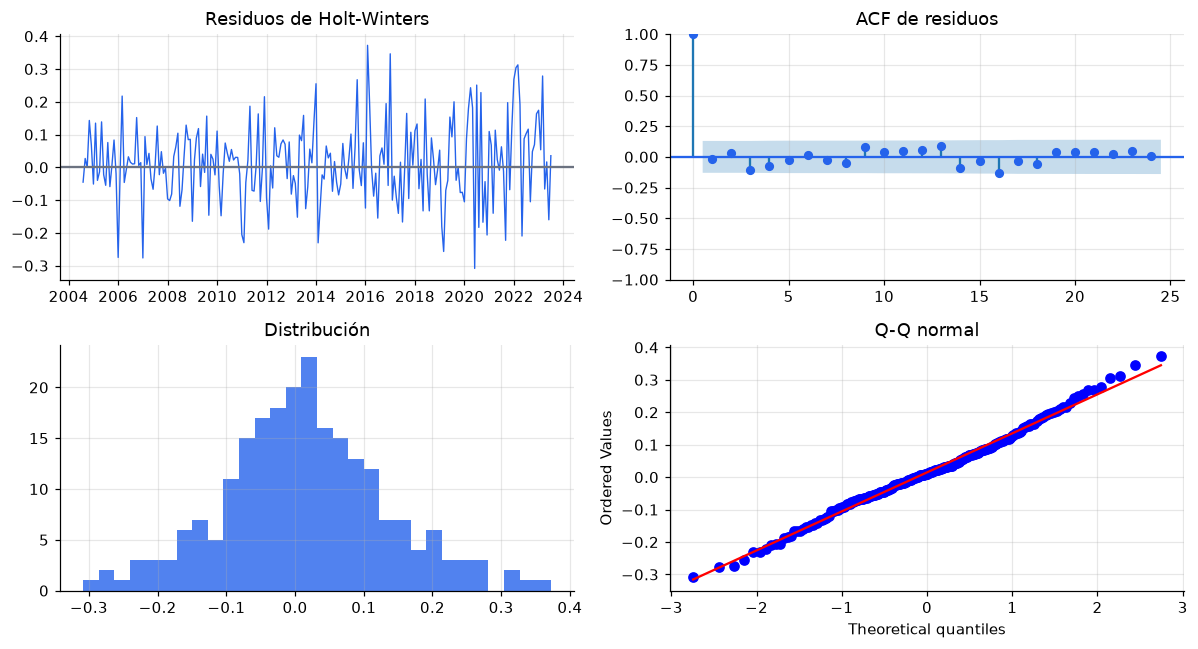

In [12]:
res = s.residuos_utiles("Holt-Winters", modelos["Holt-Winters"])
fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
ejes[0, 0].plot(res, color=AZUL, lw=.9); ejes[0, 0].axhline(0, color=GRIS); ejes[0, 0].set_title("Residuos de Holt-Winters")
plot_acf(res, lags=24, ax=ejes[0, 1], color=AZUL, title="ACF de residuos")
ejes[1, 0].hist(res, bins=30, color=AZUL, alpha=.8); ejes[1, 0].set_title("Distribución")
stats.probplot(res, dist="norm", plot=ejes[1, 1]); ejes[1, 1].set_title("Q-Q normal")
fig.tight_layout(); fig.savefig(FIG / "06_residuos.png", bbox_inches="tight"); plt.show()

## 7. Pronóstico publicado con intervalo de predicción al 95 %

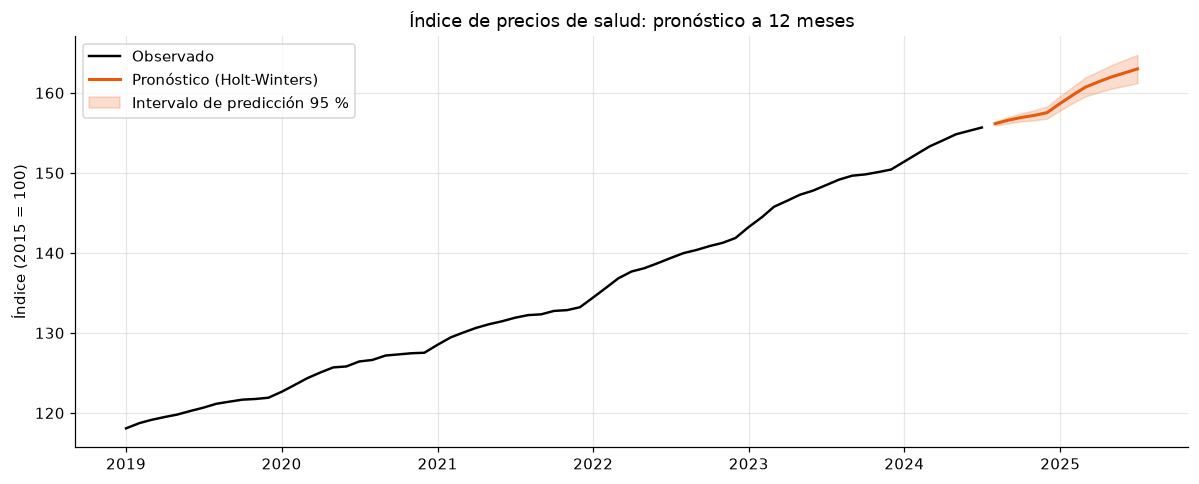

Con 95 % de confianza, entre 07/2024 y 07/2025 los precios de productos y servicios de salud en México subirían entre 3.6 % y 5.8 % (estimación central: 4.7 %). Para un consultorio que gasta $10,000 al mes en insumos, eso equivale a presupuestar entre $10,356 y $10,583 al mes un año después, si su canasta sigue al índice nacional.


,fecha,pronostico,limite_inferior_95,limite_superior_95
0,2024-08,156.15,155.90,156.41
1,2024-09,156.59,156.20,156.98
2,2024-10,156.92,156.44,157.44
3,2024-11,157.18,156.57,157.83
4,2024-12,157.54,156.79,158.31
5,2025-01,158.69,157.82,159.61
6,2025-02,159.79,158.78,160.83
7,2025-03,160.72,159.55,161.92
8,2025-04,161.39,160.09,162.71
9,2025-05,161.99,160.52,163.47


In [13]:
ajuste_final, futuro = s.pronosticar(publicado, salud, orden)
fechas = pd.to_datetime(futuro.fecha)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(salud["2019-01":], color="black", lw=1.6, label="Observado")
ax.plot(fechas, futuro.pronostico, color=NARANJA, lw=2, label=f"Pronóstico ({publicado})")
ax.fill_between(fechas, futuro.limite_inferior_95, futuro.limite_superior_95, color=NARANJA, alpha=.2, label="Intervalo de predicción 95 %")
ax.set_title("Índice de precios de salud: pronóstico a 12 meses"); ax.set_ylabel("Índice (2015 = 100)"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "07_pronostico.png", bbox_inches="tight"); plt.show()
print(s.frase_cliente(salud, futuro))
futuro.round(2)

**Para el cliente:** el intervalo dice dónde estará el índice 95 de cada 100 veces si el comportamiento de 2002–2024 se mantiene. Lo que el consultorio debe hacer con él es **presupuestar con el límite superior**: alrededor de **5.8 % más** que hoy para el mismo nivel de insumos un año después.

**Límites honestos:**

1. Es un índice **nacional** de salud que incluye servicios médicos. Una canasta dental de Colima puede subir más o menos.
2. La serie publicada termina en julio de 2024 y el pronóstico cubre agosto 2024 a julio 2025. Cuando la fuente publique meses más recientes, la captura y este notebook se vuelven a correr sin cambios de código, y se puede comparar el pronóstico contra lo que realmente pasó.
3. La varianza de los residuos creció después de 2021, así que el intervalo podría quedarse corto si la inflación vuelve a acelerarse.

In [14]:
resumen = s.ejecutar(captura)   # escribe los CSV y resumen.json en datos/oro/series_e1/
sorted(p.name for p in Path("datos/oro/series_e1").glob("*.*"))

['busqueda_arima_aic.csv',
 'comparacion_modelos.csv',
 'correlacion_cruzada.csv',
 'pronostico_prueba.csv',
 'pronostico_publicado.csv',
 'resumen.json',
 'serie_ipc_salud.csv',
 'validacion_origenes.csv']

## 8. Conclusión

| Pregunta de la rúbrica | Respuesta con evidencia |
|---|---|
| Caracterización y descomposición | Tendencia casi lineal (+4.6 % anual), estacionalidad de enero, modelo **multiplicativo** (r = 0.55 entre amplitud y nivel) |
| Estacionariedad | ADF: estacionaria con **d=1 y D=1** (p < 0.001) |
| ACF y PACF | MA estacional de orden 1 en el rezago 12 y ARMA corto, con lo que se acota la búsqueda |
| Correlación cruzada | Sin relación contemporánea con la inflación general (r = 0.02); solo efectos débiles a 8–10 meses |
| Cuatro modelos | Suavizamiento simple, Holt, Holt-Winters y SARIMA(1,1,3)(0,1,1)[12] (p, q, P, Q por AIC) |
| Selección por error | MAE, RMSE y MAPE en la prueba de 12 meses y en 3 ventanas: **Holt-Winters** tiene el menor error promedio |
| Residuos | Holt-Winters pasa Ljung-Box (p = 0.75 y 0.73) y ARCH (p = 0.08). Holt queda descartado por la puerta 3 |
| Comunicación | Pronóstico con intervalo al 95 % y la frase para el cliente de la sección 7 |

Todos los resultados están en `datos/oro/series_e1/` (CSV, `resumen.json` y figuras) para usarlos en el tablero.